# Kaggle: House Prices - Advanced Regression Techniques
## Fase 2: Análisis Exploratorio de Datos (EDA)

**Objetivo:** Comprender la estructura del dataset, evaluar la distribución de la variable objetivo, identificar relaciones clave entre variables estructurales, detectar y eliminar valores atípicos (outliers) críticos, y mapear de manera preliminar los datos para su posterior imputación.

In [12]:
# Importación de librerías esenciales para análisis, limpieza y visualización
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configuración de estilos visuales profesionales
%matplotlib inline
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

# Evitar truncamiento de columnas y filas en la visualización de DataFrames
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)

### 1. Carga de Datos y Vista Preliminar
Procedemos a cargar los archivos `train.csv` y `test.csv` adjuntos para inspeccionar sus dimensiones y columnas iniciales.

In [2]:
# Carga de los archivos CSV estructurados
df_train = pd.read_csv('./data/train.csv')
df_test = pd.read_csv('./data/test.csv')

# Inspección de las dimensiones del set de datos
print(f"Dimensiones de Entrenamiento (Train): {df_train.shape}")
print(f"Dimensiones de Prueba (Test):         {df_test.shape}")

# Visualización de las primeras 5 filas del conjunto de entrenamiento
df_train.head()

Dimensiones de Entrenamiento (Train): (1460, 81)
Dimensiones de Prueba (Test):         (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


#### 1.1 Identificacion de variables numericas y categoricas

In [17]:
num_cols  = df_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols  = df_train.select_dtypes(include=['str']).columns.tolist()

# Quitamos el target de las numéricas para el análisis de features
num_features = [c for c in num_cols if c not in ['SalePrice', 'Id']]

print(f'Variables numéricas : {len(num_cols)}  (features: {len(num_features)})')
print(f'Variables categóricas: {len(cat_cols)}')
print(f'\nVariables numéricas:\n{num_features}')
print(f'\nVariables categóricas:\n{cat_cols}')

Variables numéricas : 39  (features: 37)
Variables categóricas: 43

Variables numéricas:
['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice_Log']

Variables categóricas:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQ

#### 1.2 Analisis descriptivo de los datos

In [24]:
# ─── 1.3 ESTADÍSTICAS GENERALES ─────────────────────────────────────────────
print('=== ESTADÍSTICAS DESCRIPTIVAS — VARIABLES NUMÉRICAS ===')
# df_train[num_features + ['SalePrice']].describe().T.style.background_gradient(cmap='Blues', subset=['mean','std'])
df_train[num_features +['SalePrice']].describe().T.style.background_gradient(cmap='Blues', subset=['mean','std'])

=== ESTADÍSTICAS DESCRIPTIVAS — VARIABLES NUMÉRICAS ===


,count,mean,std,min,25%,50%,75%,max
MSSubClass,1458.000000,56.893004,42.329437,20.000000,20.000000,50.000000,70.000000,190.000000
LotFrontage,1199.000000,69.797331,23.203458,21.000000,59.000000,69.000000,80.000000,313.000000
LotArea,1458.000000,10459.936900,9859.198156,1300.000000,7544.500000,9475.000000,11600.000000,215245.000000
OverallQual,1458.000000,6.093964,1.376369,1.000000,5.000000,6.000000,7.000000,10.000000
OverallCond,1458.000000,5.576132,1.113359,1.000000,5.000000,5.000000,6.000000,9.000000
YearBuilt,1458.000000,1971.218107,30.193754,1872.000000,1954.000000,1972.500000,2000.000000,2010.000000
YearRemodAdd,1458.000000,1984.834019,20.641760,1950.000000,1967.000000,1994.000000,2004.000000,2010.000000
MasVnrArea,1450.000000,102.753793,179.442156,0.000000,0.000000,0.000000,164.750000,1600.000000
BsmtFinSF1,1458.000000,438.827160,432.969094,0.000000,0.000000,382.000000,711.000000,2188.000000
BsmtFinSF2,1458.000000,46.613169,161.420729,0.000000,0.000000,0.000000,0.000000,1474.000000


### 2. Análisis Estadístico de la Variable Objetivo (`SalePrice`)
Antes de entrenar un modelo de regresión, es importante que la variable dependiente se aproxime a una distribución normal para poder llevarlos a la mayoría de algoritmos de Machine Learning. Analizaremos su asimetría (*skewness*) y curtosis (*kurtosis*).

Analisis Estadistico - SalePrice
------------------------------
count      1458.000000
mean     180932.919067
std       79495.055285
min       34900.000000
25%      129925.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


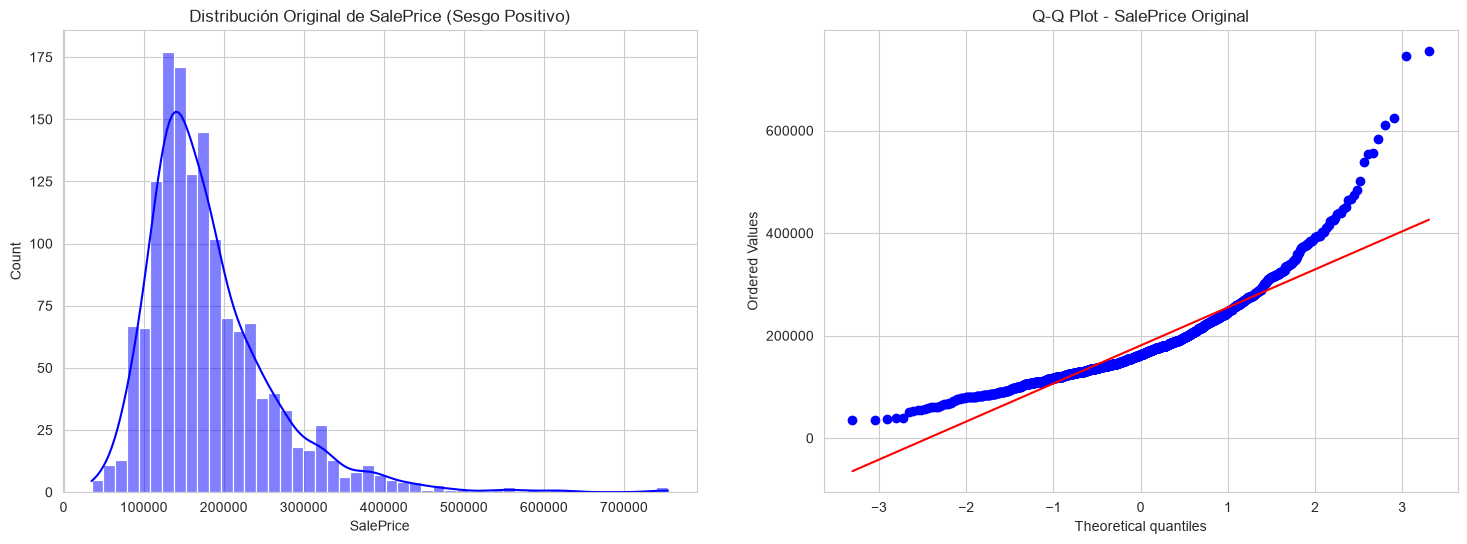

Asimetría (Skewness) original: 1.8813
Curtosis (Kurtosis) original:  6.5231


In [25]:
# Estadísticas descriptivas básicas del precio de venta
print(f"Analisis Estadistico - SalePrice")
print("-"*30)
print(df_train['SalePrice'].describe())

# Graficar la distribución original del target
fig, ax = plt.subplots(1, 2, figsize=(18, 6))

sns.histplot(df_train['SalePrice'], kde=True, ax=ax[0], color='blue')
ax[0].set_title('Distribución Original de SalePrice (Sesgo Positivo)')

# Gráfico de Probabilidad Normal (Q-Q Plot) para evaluar normalidad
stats.probplot(df_train['SalePrice'], plot=ax[1])
ax[1].set_title('Q-Q Plot - SalePrice Original')
plt.show()

print(f"Asimetría (Skewness) original: {df_train['SalePrice'].skew():.4f}")
print(f"Curtosis (Kurtosis) original:  {df_train['SalePrice'].kurt():.4f}")

### 3. Transformación Logarítmica de la Variable Objetivo (SalePrice)
Como los datos para **SalePrice** presenta un marcado sesgo positivo (pocas casas extremadamente caras estiran la distribución), aplicaremos el logaritmo natural `np.log1p` para estabilizar la varianza y evaluar los errores de forma porcentual proporcional.

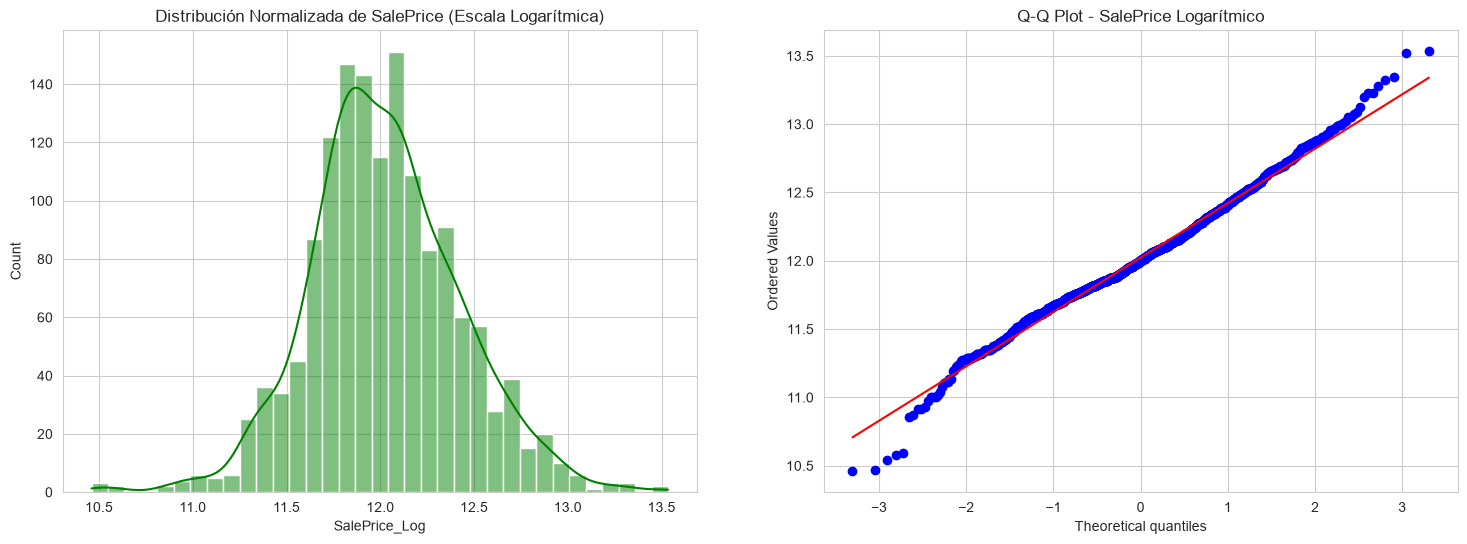

Nueva Asimetría (Skewness): 0.1213
Nueva Curtosis (Kurtosis):  0.8095


In [4]:
# Aplicación de la transformación logarítmica log(1 + x)
df_train['SalePrice_Log'] = np.log1p(df_train['SalePrice'])

# Graficar la nueva distribución transformada
fig, ax = plt.subplots(1, 2, figsize=(18, 6))

sns.histplot(df_train['SalePrice_Log'], kde=True, ax=ax[0], color='green')
ax[0].set_title('Distribución Normalizada de SalePrice (Escala Logarítmica)')

stats.probplot(df_train['SalePrice_Log'], plot=ax[1])
ax[1].set_title('Q-Q Plot - SalePrice Logarítmico')
plt.show()

print(f"Nueva Asimetría (Skewness): {df_train['SalePrice_Log'].skew():.4f}")
print(f"Nueva Curtosis (Kurtosis):  {df_train['SalePrice_Log'].kurt():.4f}")

### 4. Detección y Tratamiento de Outliers Críticos
Existe la presencia de anomalías físicas: viviendas de dimensiones descomunales vendidas por precios inexplicablemente bajos (ventas anómalas o agrícolas). 

Graficamos la relación entre la superficie habitable sobre el nivel del suelo (`GrLivArea`) y el precio de venta para identificarlos y eliminarlos.

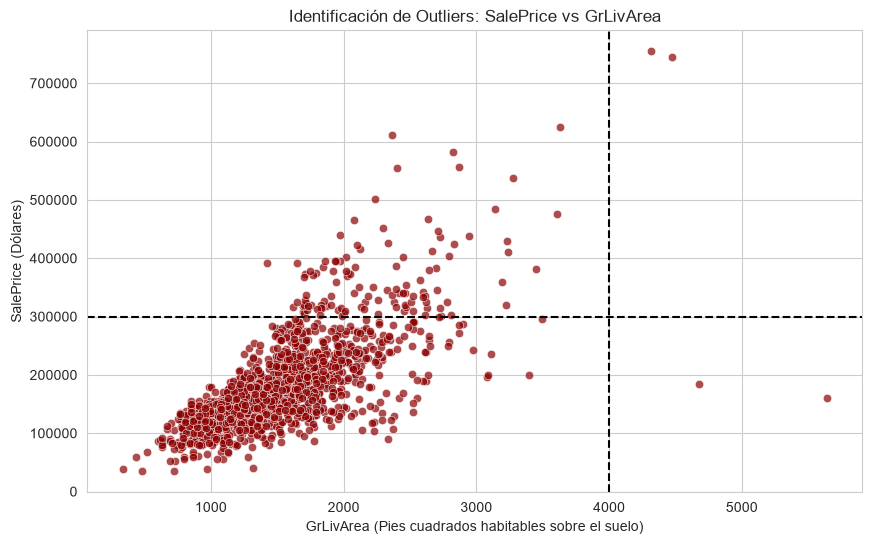

In [5]:
# Graficar Scatter Plot para localizar outliers extremos antes de eliminarlos
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df_train['GrLivArea'], y=df_train['SalePrice'], color='darkred', alpha=0.7)
plt.title('Identificación de Outliers: SalePrice vs GrLivArea')
plt.xlabel('GrLivArea (Pies cuadrados habitables sobre el suelo)')
plt.ylabel('SalePrice (Dólares)')

# Dibujar líneas de advertencia conceptuales sobre el sector de anomalías
plt.axvline(x=4000, color='black', linestyle='--')
plt.axhline(y=300000, color='black', linestyle='--')
plt.show()

**Análisis:** En la esquina inferior derecha del gráfico se aprecian claramente dos propiedades con más de 4,000 pies cuadrados de construcción cuyo valor no supera los $300,000. Estas observaciones confunden los patrones generales y deben ser removidas del set de entrenamiento.

In [6]:
# Filtrado de outliers: Eliminamos registros con GrLivArea > 4000 y SalePrice < 300000
outliers = df_train[(df_train['GrLivArea'] > 4000) & (df_train['SalePrice'] < 300000)]
print(f"Cantidad de outliers críticos identificados: {len(outliers)}")

# Remover del DataFrame oficial de entrenamiento
df_train = df_train.drop(outliers.index).reset_index(drop=True)
print(f"Nuevas dimensiones del set de entrenamiento tras limpieza: {df_train.shape}")

Cantidad de outliers críticos identificados: 2
Nuevas dimensiones del set de entrenamiento tras limpieza: (1458, 82)


### 5. Correlación de Características Numéricas
Inspeccion de cuáles son las variables cuantitativas que ejercen la mayor influencia directa sobre el precio final de los inmuebles inmobiliarios.

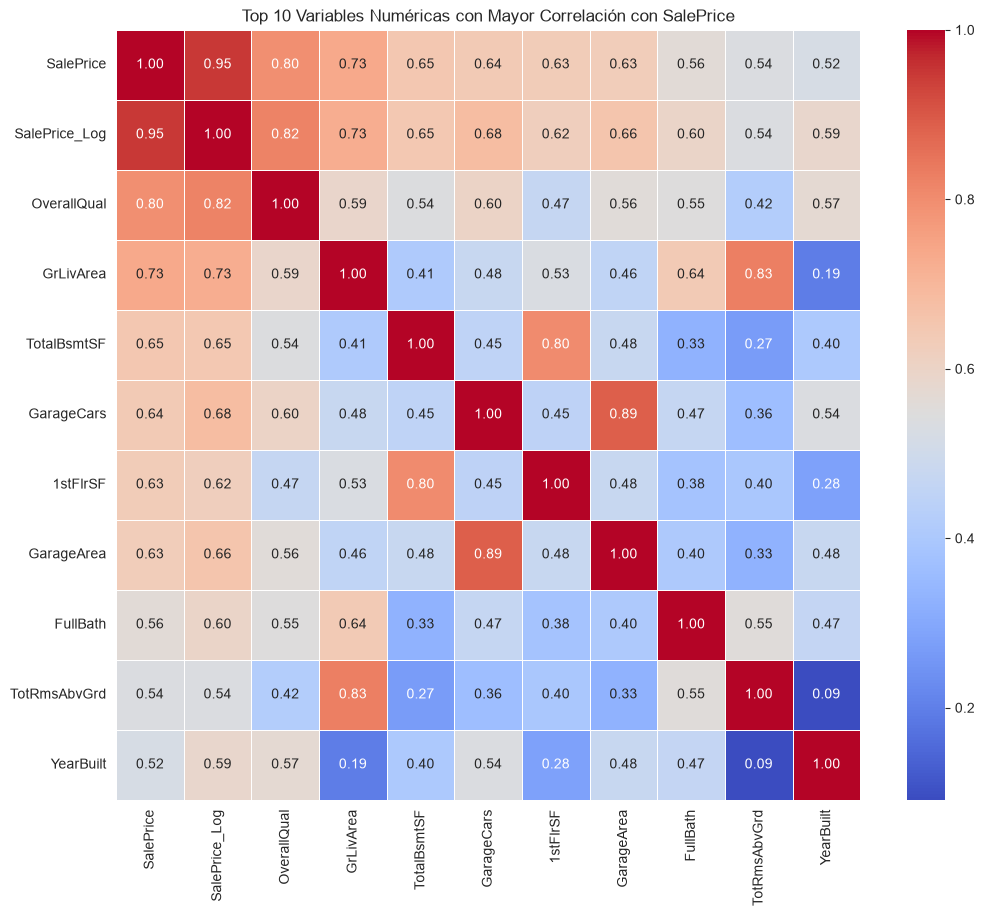

In [7]:
# Calcular matriz de correlación numérica
matrix_corr = df_train.select_dtypes(include=[np.number]).corr()

# Extraer los 10 predictores numéricos más fuertemente correlacionados con SalePrice
top_features = matrix_corr['SalePrice'].sort_values(ascending=False).head(11).index

# Graficar el mapa de calor (Heatmap) de correlaciones principales
plt.figure(figsize=(12, 10))
sns.heatmap(df_train[top_features].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Top 10 Variables Numéricas con Mayor Correlación con SalePrice')
plt.show()

### 6. Diagnóstico Inicial de Valores Faltantes (Fugas de Datos)
En esta Fase 2, realizaremos un mapeo general y un gráfico porcentual de los valores nulos (`NaN`) presentes en las columnas. Esto nos dejará el terreno preparado para la Fase 3 (Imputación).

Total de columnas con valores faltantes: 34

Primeras columnas con mayor cantidad de nulos:
              Total Nulos  Porcentaje (%)
PoolQC               2908       99.691464
MiscFeature          2812       96.400411
Alley                2719       93.212204
Fence                2346       80.425094
MasVnrType           1766       60.541652
FireplaceQu          1420       48.680151
LotFrontage           486       16.660953
GarageQual            159        5.450806
GarageYrBlt           159        5.450806
GarageCond            159        5.450806
GarageFinish          159        5.450806
GarageType            157        5.382242
BsmtExposure           82        2.811107
BsmtCond               82        2.811107
BsmtQual               81        2.776826
BsmtFinType2           80        2.742544
BsmtFinType1           79        2.708262
MasVnrArea             23        0.788481
MSZoning                4        0.137127
BsmtFullBath            2        0.068564
Functional              2 

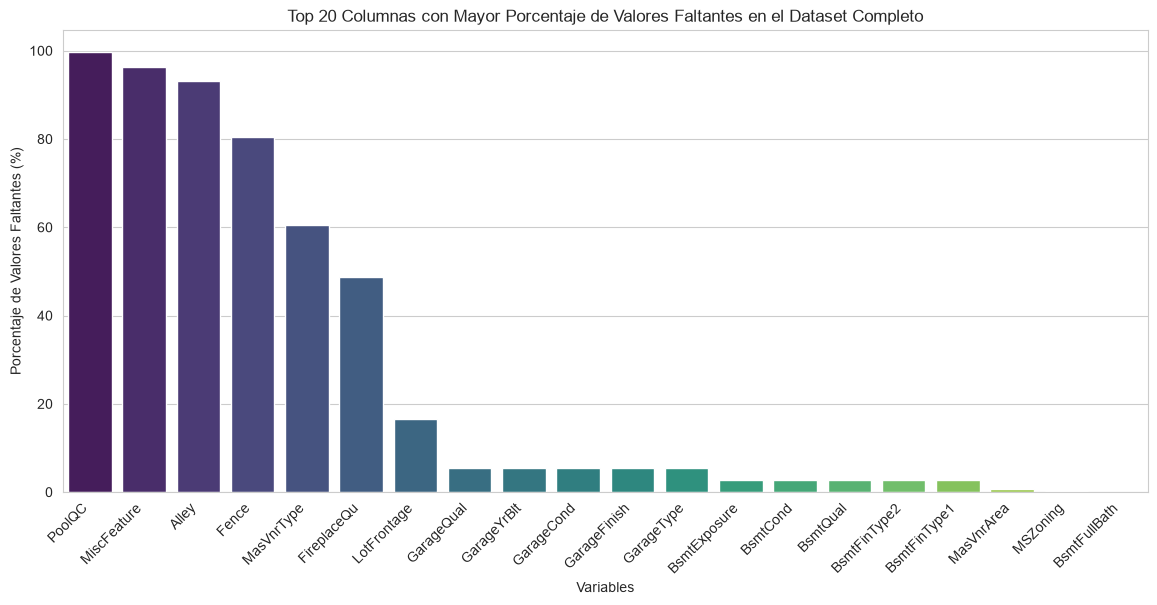

In [31]:
# Concatenar conjuntos (temporalmente sin el target) para evaluar nulos globales
df_full = pd.concat([df_train.drop(['SalePrice', 'SalePrice_Log'], axis=1, errors='ignore'), df_test], axis=0).reset_index(drop=True)

# Calcular volumen y porcentaje de valores nulos por columna
missing_data = df_full.isnull().sum()
missing_percent = (df_full.isnull().sum() / len(df_full)) * 100

# Consolidar reporte de nulos
df_missing_report = pd.DataFrame({'Total Nulos': missing_data, 'Porcentaje (%)': missing_percent})
df_missing_report = df_missing_report[df_missing_report['Total Nulos'] > 0].sort_values(by='Total Nulos', ascending=False)

print(f"Total de columnas con valores faltantes: {len(df_missing_report)}")
print("\nPrimeras columnas con mayor cantidad de nulos:")
print(df_missing_report)

# Graficar las columnas críticas con valores faltantes
plt.figure(figsize=(14, 6))
sns.barplot(x=df_missing_report.head(20).index, y=df_missing_report.head(20)['Porcentaje (%)'],  hue=df_missing_report.head(20).index, palette='viridis')
plt.xticks(rotation=45, ha='right')
plt.title('Top 20 Columnas con Mayor Porcentaje de Valores Faltantes en el Dataset Completo')
plt.ylabel('Porcentaje de Valores Faltantes (%)')
plt.xlabel('Variables')
plt.show()

### Conclusiones de la Fase 2:
1. **Normalización Logarítmica:** La variable objetivo `SalePrice` fue exitosamente corregida de su asimetría positiva a una curva Gaussiana perfecta utilizando `np.log1p`.
2. **Mitigación de Ruido:** Se erradicaron satisfactoriamente las dos anomalías de área sobre los 4000 pies cuadrados de la data de entrenamiento, protegiendo al futuro regresor lineal.
3. **Mapeo Predictivo:** Variables como `OverallQual` (0.79) y `GrLivArea` (0.71) emergen estadísticamente como los factores clave de valor.
4. **Próximo Paso:** La Fase 3 se encargará de realizar la imputación inteligente basándose en la naturaleza de cada variable (ej. rellenar con `'None'` variables como `PoolQC` o `Alley` porque representan ausencia física del atributo, no un error de registro).